In [1]:
import os

In [1]:
import meshio
import numpy as np
import deepxde as dde
import matplotlib.pyplot as plt

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


In [2]:
mesh = meshio.read("pipe_bend2.msh")

all_points = mesh.points[:, 0:2]

print("----Dignostics----")
print("Available keys in cell_sets_dict:", list(mesh.cell_sets_dict.keys()))
print("Available keys in field_data:", list(mesh.field_data.keys()))


----Dignostics----
Available keys in cell_sets_dict: []
Available keys in field_data: ['inlet', 'outlet', 'walls', 'fluid']


This code scales the values which are big like 150 mm for length and nothing else. This step is used to chances of coming [nan, nan] in training process

In [4]:
mesh = meshio.read("pipe_bend2.msh")

# 1. Compute global normalization bounds from raw mesh points
raw_coords = mesh.points
X_min_vals = np.min(raw_coords, axis=0)
spatial_span = np.max(raw_coords) - np.min(raw_coords)

# 2. Rescale to safely sit between 0.0 and 1.0 (Fixes the exp overflow!)
all_coords = (raw_coords - X_min_vals) / spatial_span

inlet_nodes = set()
outlet_nodes = set()
walls_nodes = set()
fluid_nodes = set()

# 3. Precise dictionary mapping (15=Inlet, 16=Outlet, 17=Walls, 19=Fluid)
group_mapping = {15: inlet_nodes, 16: outlet_nodes, 17: walls_nodes, 19: fluid_nodes}

for block_idx, cell_block in enumerate(mesh.cells):
    if "gmsh:physical" in mesh.cell_data:
        tags = mesh.cell_data["gmsh:physical"][block_idx]
        elements_node_indices = cell_block.data
        
        for i, tag in enumerate(tags):
            if tag in group_mapping:
                group_mapping[tag].update(elements_node_indices[i])

# 4. Extract unique scaled sub-arrays (Double check indices!)
X_inlet  = all_coords[list(inlet_nodes)][:, 0:3]
X_outlet = all_coords[list(outlet_nodes)][:, 0:3]  # <-- Fixed to use outlet_nodes
X_walls  = all_coords[list(walls_nodes)][:, 0:3]
X_domain = all_coords[list(fluid_nodes)][:, 0:3]

print("--- Point Count Verification ---")
print(f"Fluid Domain Nodes: {X_domain.shape[0]}")
print(f"Inlet Border Nodes: {X_inlet.shape[0]}")
print(f"Outlet Border Nodes:{X_outlet.shape[0]}")
print(f"Wall Border Nodes:  {X_walls.shape[0]}")

""" This code is to create dense boundary
# Quick trick to double your boundary resolution by inserting midpoints
midpoints = (X_walls[:-1] + X_walls[1:]) / 2.0
X_walls_dense = np.vstack((X_walls, midpoints))

# Re-combine into your training coordinates
X_all_training = np.vstack((X_domain, X_inlet, X_outlet, X_walls_dense))
geom = dde.geometry.PointCloud(X_all_training)
# 5. Build Unified Training Set"""
X_all_training = np.vstack((X_domain, X_inlet, X_outlet, X_walls))
print(f"Total Combined Training Nodes: {X_all_training.shape[0]} <-- This should match your original count!")

geom = dde.geometry.PointCloud(X_all_training)



--- Point Count Verification ---
Fluid Domain Nodes: 13792
Inlet Border Nodes: 179
Outlet Border Nodes:181
Wall Border Nodes:  5591
Total Combined Training Nodes: 19743 <-- This should match your original count!


In [7]:
def navier_stokes_3d(x, y):
    u = y[:, 0:1]
    v = y[:, 1:2]
    w = y[:, 2:3]
    p = y[:, 3:4]
    
    # Kinematic viscosity (adjust based on your fluid property, e.g., water ~ 1e-6)
    nu = 0.001 
    
    # First derivatives
    du_x = dde.grad.jacobian(y, x, i=0, j=0)
    du_y = dde.grad.jacobian(y, x, i=0, j=1)
    du_z = dde.grad.jacobian(y, x, i=0, j=2)
    
    dv_x = dde.grad.jacobian(y, x, i=1, j=0)
    dv_y = dde.grad.jacobian(y, x, i=1, j=1)
    dv_z = dde.grad.jacobian(y, x, i=1, j=2)
    
    dw_x = dde.grad.jacobian(y, x, i=2, j=0)
    dw_y = dde.grad.jacobian(y, x, i=2, j=1)
    dw_z = dde.grad.jacobian(y, x, i=2, j=2)
    
    dp_x = dde.grad.jacobian(y, x, i=3, j=0)
    dp_y = dde.grad.jacobian(y, x, i=3, j=1)
    dp_z = dde.grad.jacobian(y, x, i=3, j=2)
    
    # Second derivatives (Laplacians for viscous forces)
    du_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)
    du_yy = dde.grad.hessian(y, x, component=0, i=1, j=1)
    du_zz = dde.grad.hessian(y, x, component=0, i=2, j=2)
    
    dv_xx = dde.grad.hessian(y, x, component=1, i=0, j=0)
    dv_yy = dde.grad.hessian(y, x, component=1, i=1, j=1)
    dv_zz = dde.grad.hessian(y, x, component=1, i=2, j=2)
    
    dw_xx = dde.grad.hessian(y, x, component=2, i=0, j=0)
    dw_yy = dde.grad.hessian(y, x, component=2, i=1, j=1)
    dw_zz = dde.grad.hessian(y, x, component=2, i=2, j=2)
    
    # 3D Navier-Stokes Momentum Equations
    momentum_x = u * du_x + v * du_y + w * du_z + dp_x - nu * (du_xx + du_yy + du_zz)
    momentum_y = u * dv_x + v * dv_y + w * dv_z + dp_y - nu * (dv_xx + dv_yy + dv_zz)
    momentum_z = u * dw_x + v * dw_y + w * dw_z + dp_z - nu * (dw_xx + dw_yy + dw_zz)
    
    # 3D Continuity Equation (Incompressible flow constraint)
    continuity = du_x + dv_y + dw_z
    
    return [momentum_x, momentum_y, momentum_z, continuity]




In [18]:
# Components: 0=u, 1=v, 2=w, 3=p

# Inlet Conditions: u=0.0, v=0.0, w=1.0
vals_inlet_u = np.zeros((len(X_inlet), 1))
vals_inlet_v = np.zeros((len(X_inlet), 1))
vals_inlet_w = np.ones((len(X_inlet), 1))

# Wall No-slip Conditions: u=0.0, v=0.0, w=0.0
vals_walls_u = np.zeros((len(X_walls), 1))
vals_walls_v = np.zeros((len(X_walls), 1))
vals_walls_w = np.zeros((len(X_walls), 1))

# Outlet Condition: p=0.0
vals_outlet_p = np.zeros((len(X_outlet), 1))


# 2. Pass the raw data matrices into PointSetBC (No lambdas!)
bc_inlet_u = dde.icbc.PointSetBC(X_inlet, vals_inlet_u, component=0)
bc_inlet_v = dde.icbc.PointSetBC(X_inlet, vals_inlet_v, component=1)
bc_inlet_w = dde.icbc.PointSetBC(X_inlet, vals_inlet_w, component=2)

bc_walls_u = dde.icbc.PointSetBC(X_walls, vals_walls_u, component=0)
bc_walls_v = dde.icbc.PointSetBC(X_walls, vals_walls_v, component=1)
bc_walls_w = dde.icbc.PointSetBC(X_walls, vals_walls_w, component=2)
"""
# This code is for denser boundary
bc_walls_u = dde.icbc.PointSetBC(X_walls_dense, np.zeros(len(X_walls_dense)), component=0)
bc_walls_v = dde.icbc.PointSetBC(X_walls_dense, np.zeros(len(X_walls_dense)), component=1)
bc_walls_w = dde.icbc.PointSetBC(X_walls_dense, np.zeros(len(X_walls_dense)), component=2)"""

bc_outlet_p = dde.icbc.PointSetBC(X_outlet, vals_outlet_p, component=3)

bcs = [bc_inlet_u, bc_inlet_v, bc_inlet_w, bc_walls_u, bc_walls_v, bc_walls_w, bc_outlet_p]
# bcs = [bc_inlet_w, bc_walls_u, bc_walls_v, bc_walls_w, bc_outlet_p]

In [19]:
data = dde.data.PDE(
    geom,
    navier_stokes_3d,
    bcs,
    num_domain=0,
    num_boundary=0,
    anchors=X_all_training  # <--- This is where your custom points belong!
)



In [20]:
loss_weights = [
    1.0, 1.0, 1.0, 1.0,    
    50.0, 50.0, 50.0,        
    5000.0, 5000.0, 5000.0, 
    10.0,             
    ]

In [31]:
net = dde.nn.FNN([3, 128, 128, 128, 4], "tanh", "Glorot uniform")
model = dde.Model(data, net)

In [32]:
class SoftmaxAdaptiveWeights(dde.callbacks.Callback):
    def __init__(self, model, every_n_epochs=100, alpha_0=1.0, gamma=0.999):
        super().__init__()
        self.model = model
        self.every_n_epochs = every_n_epochs
        self.alpha = alpha_0
        self.gamma = gamma
        self.epoch = 0

    def on_epoch_end(self):
        self.epoch += 1
        if self.epoch % self.every_n_epochs != 0:
            return
        if len(self.model.losshistory.loss_train) == 0:
            return
        current_losses = self.model.losshistory.loss_train[-1]
        # exp_terms = np.exp(self.alpha * np.array(current_losses))
        # new_weights = exp_terms / (np.sum(exp_terms) + 1e-8)
        
        # --- Replace the broken lines inside your custom Callback class ---

        # 1. Isolate the current losses array
        current_losses = np.array(current_losses)

        # 2. Subtract the max value to guarantee stability (Prevents e^105 overflow!)
        shifted_losses = self.alpha * (current_losses - np.max(current_losses))

        # 3. Compute safe exponential terms
        exp_terms = np.exp(shifted_losses)

        # 4. Safe weight allocation
        new_weights = exp_terms / (np.sum(exp_terms) + 1e-8)


        self.alpha *= self.gamma
        self.model.loss_weights = new_weights.tolist()
        # print(f"Epoch {self.epoch}: Adaptive weights updated to {new_weights.tolist()}, alpha decayed to {self.alpha:.4f}")

adaptive_callback = SoftmaxAdaptiveWeights(model, every_n_epochs=20)

In [ ]:
# model.compile("adam", lr=0.001, loss_weights=model.loss_weights)

# losshistory, train_state = model.train(iterations=1000,display_every=300, callbacks=[adaptive_callback])

dde.optimizers.config.set_LBFGS_options(maxiter=2000)
model.compile("L-BFGS", loss_weights=model.loss_weights)
losshistory, train_state = model.train(display_every=50)

Compiling model...
'compile' took 0.000472 s

Training model...

0         [2.73e-02, 3.42e-03, 1.97e-02, 1.85e-05, 5.01e-04, 3.76e-04, 9.91e-01, 1.82e-03, 5.80e-02, 4.86e-04, 3.08e-02]    [2.73e-02, 3.42e-03, 1.97e-02, 1.85e-05, 5.01e-04, 3.76e-04, 9.91e-01, 1.82e-03, 5.80e-02, 4.86e-04, 3.08e-02]    []  
1000      [4.68e-04, 4.06e-04, 3.69e-03, 6.04e-04, 2.82e-03, 2.77e-03, 4.37e-03, 2.40e-03, 2.69e-03, 4.10e-02, 1.69e-07]    [4.68e-04, 4.06e-04, 3.69e-03, 6.04e-04, 2.82e-03, 2.77e-03, 4.37e-03, 2.40e-03, 2.69e-03, 4.10e-02, 1.69e-07]    []  


Rendering loss tracking timeline graphs...


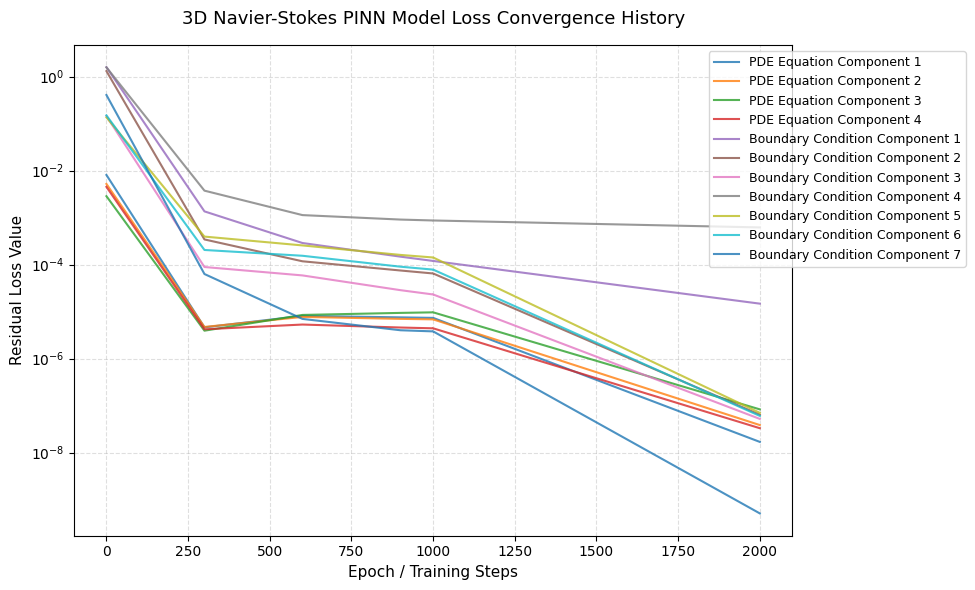

In [16]:
# 1. Access the saved loss data arrays from your DeepXDE training history
# (Ensure you ran: losshistory, train_state = model.train(...) before this)
steps = np.array(losshistory.steps)
loss_train = np.array(losshistory.loss_train)  # Shape: (Num_Steps, Num_Loss_Functions)

# 2. Set up the plotting window canvas
fig, ax = plt.subplots(figsize=(10, 6))

# 3. Graph the individual loss tracks dynamically
# DeepXDE tracks PDE losses first, followed by BC losses
num_losses = loss_train.shape[1]

for i in range(num_losses):
    if i < 4:
        # The first 4 losses belong to the 3D Navier-Stokes equations
        label_name = f"PDE Equation Component {i+1}"
    else:
        # The remaining 7 losses belong to your PointSetBC constraints
        label_name = f"Boundary Condition Component {i-3}"
        
    ax.plot(steps, loss_train[:, i], label=label_name, alpha=0.8, linewidth=1.5)

# 4. Format the plot with a logarithmic scale (crucial for PINN optimization views)
ax.set_yscale("log")
ax.set_xlabel("Epoch / Training Steps", fontsize=11)
ax.set_ylabel("Residual Loss Value", fontsize=11)
ax.set_title("3D Navier-Stokes PINN Model Loss Convergence History", fontsize=13, pad=15)

# Style configuration
ax.grid(True, which="both", linestyle="--", alpha=0.4)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.0), fontsize=9)

plt.tight_layout()
print("Rendering loss tracking timeline graphs...")
plt.show()


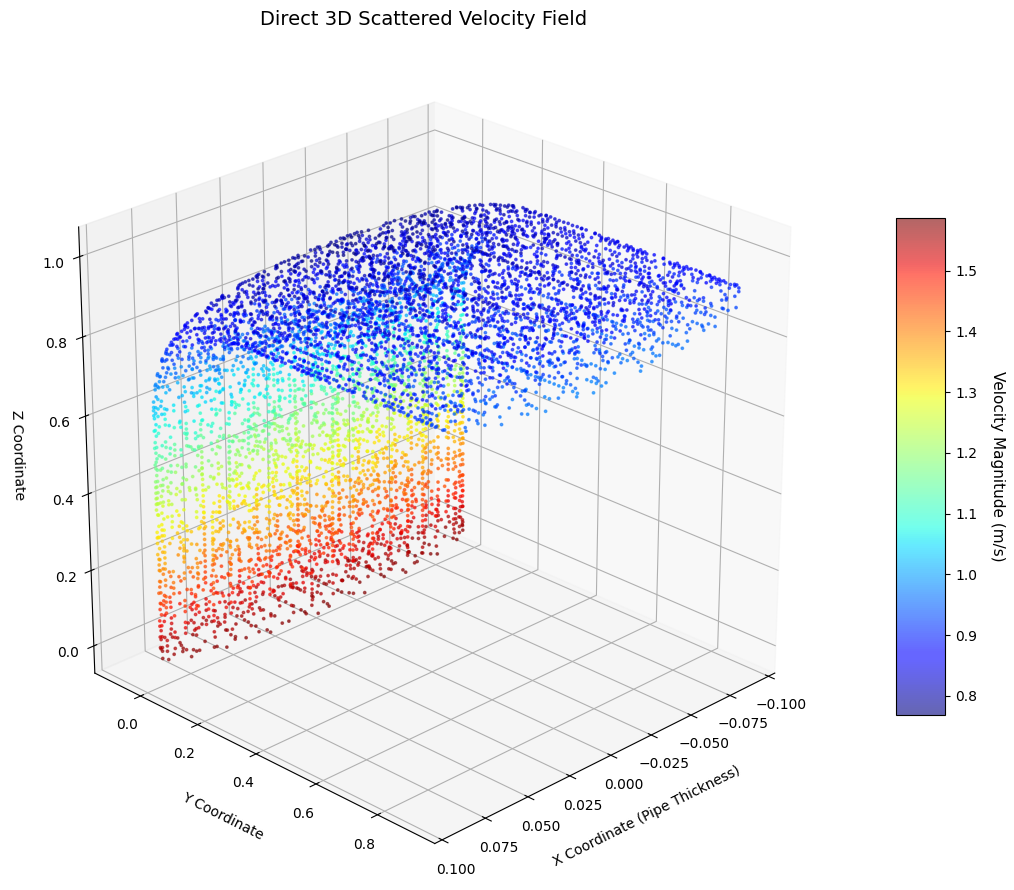

In [21]:
# 1. Generate model predictions for your true domain coordinates
predictions = model.predict(X_domain)
u_pred, v_pred, w_pred = predictions[:, 0], predictions[:, 1], predictions[:, 2]

# Calculate the True Velocity Magnitude for color mapping
vel_magnitude = np.sqrt(u_pred**2 + v_pred**2 + w_pred**2)

# 2. Initialize a 3D Canvas
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# 3. Scatter the points directly using their true X, Y, Z coordinates
# c=vel_magnitude maps the velocity array directly to the colormap colors
# [::2] downsamples the points slightly so the plot remains responsive to rotate
sc = ax.scatter(X_domain[::2, 0], X_domain[::2, 1], X_domain[::2, 2], 
                c=vel_magnitude[::2], cmap='jet', s=3, alpha=0.6)

# 4. Add a clean, descriptive Colorbar
cbar = fig.colorbar(sc, ax=ax, shrink=0.6, aspect=10)
cbar.set_label('Velocity Magnitude (m/s)', rotation=270, labelpad=20, fontsize=11)

# 5. Label your physical axes based on your Gmsh data layout
ax.set_xlabel('X Coordinate (Pipe Thickness)', fontsize=10, labelpad=10)
ax.set_ylabel('Y Coordinate', fontsize=10, labelpad=10)
ax.set_zlabel('Z Coordinate', fontsize=10, labelpad=10)
ax.set_title("Direct 3D Scattered Velocity Field", fontsize=14, pad=20)

# Adjust the viewing angle if needed (elevation, azimuth)
ax.view_init(elev=25, azim=45)

# Force equal spatial aspect ratios so the L-bend pipe does not look stretched
ax.set_box_aspect([1,1,1]) 

plt.tight_layout()
plt.show()


Rendering raw 2D node map window...


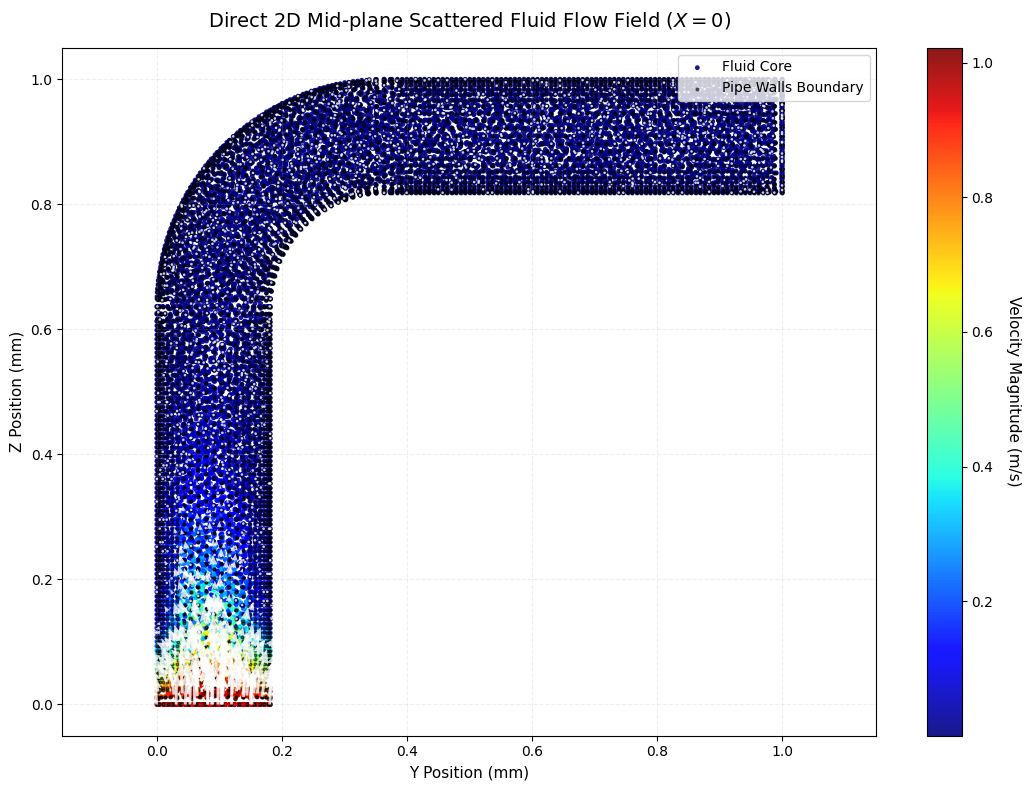

In [27]:
# 1. Predict the flow fields using your trained model
predictions = model.predict(X_domain)
u_pred, v_pred, w_pred = predictions[:, 0], predictions[:, 1], predictions[:, 2]
vel_magnitude = np.sqrt(u_pred**2 + v_pred**2 + w_pred**2)

# 2. Extract a true 2D Mid-plane Slice (Points where X is near 0)
# Adjust atol (e.g., 2.0 to 5.0) depending on how thick your mesh nodes are near the center
mid_plane_mask = np.isclose(X_domain[:, 0], 0.0, atol=4.0)

y_slice = X_domain[mid_plane_mask, 1]
z_slice = X_domain[mid_plane_mask, 2]
vel_slice = vel_magnitude[mid_plane_mask]

# Extract directional velocities for flow arrows
v_dir_slice = v_pred[mid_plane_mask]
w_dir_slice = w_pred[mid_plane_mask]

# 3. Extract wall boundary nodes to draw a crisp outer outline frame
wall_mask = np.isclose(X_walls[:, 0], 0.0, atol=4.0)
y_walls = X_walls[wall_mask, 1]
z_walls = X_walls[wall_mask, 2]

# 4. Initialize the clean 2D Canvas
fig, ax = plt.subplots(figsize=(11, 8))

# 5. Plot the fluid nodes directly using high-density scattering (Replaces contourf)
# s=12 makes the dots large enough to blend together into a solid color field
sc = ax.scatter(y_slice, z_slice, c=vel_slice, cmap='jet', s=12, alpha=0.9, edgecolors='none', label='Fluid Core')

# 6. Add a professional colorbar
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label('Velocity Magnitude (m/s)', rotation=270, labelpad=20, fontsize=11)

# 7. Draw the sharp black structural walls outline (Prevents bleeding visibility)
ax.scatter(y_walls, z_walls, color='black', s=4, alpha=0.5, label='Pipe Walls Boundary')

# 8. Overlay Flow Direction Arrows (Quiver Plot)
# [::10] skips points directly from your true node array to avoid clutter
skip = 10
ax.quiver(y_slice[::skip], z_slice[::skip], v_dir_slice[::skip], w_dir_slice[::skip], 
          color='white', alpha=0.8, scale=25, width=0.0035, headwidth=4)

# 9. Format labels and display
ax.set_title("Direct 2D Mid-plane Scattered Fluid Flow Field ($X=0$)", fontsize=14, pad=15)
ax.set_xlabel("Y Position (mm)", fontsize=11)
ax.set_ylabel("Z Position (mm)", fontsize=11)

ax.axis('equal')  # Strict 1:1 ratio ensures your L-bend stays a true 90-degrees
ax.grid(True, linestyle='--', alpha=0.2)
ax.legend(loc="upper right")

plt.tight_layout()
print("Rendering raw 2D node map window...")
plt.show()
